# 03 - Inpainting baselines vs a diffusion model

**Task:** given a 0.36 s sensor-2 spectrogram patch with 1-2 dropouts of 10-100 ms (all frequencies; two overlapping dropouts merge into one gap of up to ~200 ms), reconstruct the missing frames. Masks are fixed, so every method sees exactly the same gaps. Data and rules: see notebook 02.

**Methods**

| Method | What it does |
|---|---|
| `mean` | fills the gap with the per-frequency mean of the observed frames of the same patch |
| `linear` | per-frequency linear interpolation across the gap (edge value held at the patch border) |
| `diffusion` | one RePaint sample from an unconditional DDPM trained on clean *training-session* patches |

**Evaluation set:** `test` = 3 held-out IMI sessions (never seen in training). The model was trained on the IMI training sessions only.

**Metrics** (all over the *missing* frames only)
* `MAE` / `RMSE` in dB over all bins, and `MAE low` over 0-3 kHz where the energy is.
* `profile_corr`: does the method recover the harmonic stripes at the right frequencies (correlation of gap-averaged spectra)?
* `std_ratio`: is the texture realistic? Predicted temporal std in the gap divided by the true one (1 = realistic, 0 = a blur).

Error metrics reward blurry, averaged fills and punish realistic but non-identical texture, so read MAE together with `std_ratio`. Section 7 adds a more direct test of realism: how easily a detector can tell a filled gap from the real signal.

## 1. Setup and load

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
try:
    import mtcut
except ImportError:  # package not installed (`pip install -e .`): use the source tree
    sys.path.insert(0, str(ROOT / "src"))
    import mtcut

from mtcut.config import PROCESSED_DIR
from mtcut.inpaint import LOW_BAND_BINS, MASKED_DIR, load_patches
from mtcut.masking import BIN_HZ, FRAME_S, N_BINS, N_FRAMES, apply_mask

plt.rcParams.update({"figure.dpi": 100})
METHODS = ["mean", "linear", "diffusion"]
COLORS = dict(zip(METHODS, ["tab:gray", "tab:blue", "tab:orange"]))

metrics = pd.read_csv(MASKED_DIR / "inpaint_metrics.csv")
preds = np.load(MASKED_DIR / "inpaint_preds.npz")
log = pd.read_csv(PROCESSED_DIR / "diffusion" / "train_log.csv")
data = {s: load_patches(s) for s in ["test"]}
print(metrics.groupby("split").patch_idx.nunique().to_dict(), "patches evaluated;", len(log), "log rows; trained", int(log.step.iloc[-1]), "steps in", round(log.minutes.iloc[-1]), "min")

{'test': 144} patches evaluated; 18 log rows; trained 8643 steps in 35 min


## 2. Training curve

Epsilon-prediction MSE on the training batches (noisy: random timesteps) and on the validation sessions with fixed noise (EMA weights). It only needs to show the model is learning and not diverging; the real test is the inpainting results below.

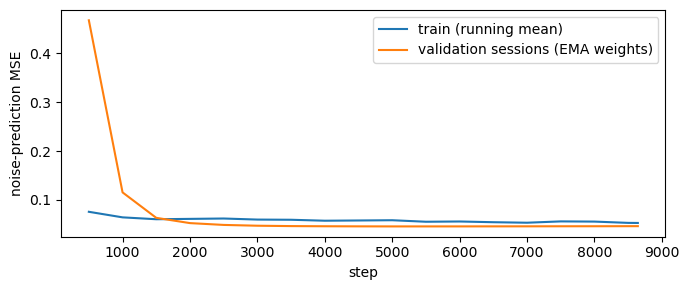

In [2]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(log.step, log.train_loss, label="train (running mean)")
ax.plot(log.step, log.val_loss_ema, label="validation sessions (EMA weights)")
ax.set_xlabel("step"); ax.set_ylabel("noise-prediction MSE"); ax.legend(); plt.tight_layout(); plt.show()

## 3. Headline results

mae_db  rmse_db  mae_low_db  profile_corr  std_ratio
test mean         3.32     4.57        3.75          0.99       0.00
     linear       3.83     5.41        4.34          0.98       0.40
     diffusion    4.35     6.12        5.30          0.97       0.88

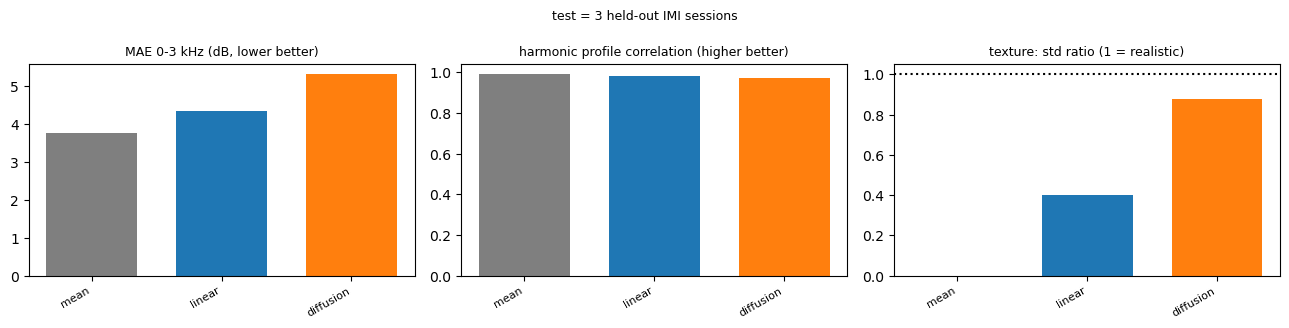

In [3]:
cols = ["mae_db", "rmse_db", "mae_low_db", "profile_corr", "std_ratio"]
tab = (metrics.groupby(["split", "method"])[cols].mean().reindex(pd.MultiIndex.from_product([["test"], METHODS])).round(2))
display(tab)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for k, (col, title) in enumerate([("mae_low_db", "MAE 0-3 kHz (dB, lower better)"), ("profile_corr", "harmonic profile correlation (higher better)"), ("std_ratio", "texture: std ratio (1 = realistic)")]):
    vals = [tab.loc[("test", m), col] for m in METHODS]
    ax[k].bar(np.arange(len(METHODS)), vals, 0.7, color=[COLORS[m] for m in METHODS])
    ax[k].set_xticks(range(len(METHODS))); ax[k].set_xticklabels(METHODS, rotation=30, ha="right", fontsize=8); ax[k].set_title(title, fontsize=9)
    if col == "std_ratio": ax[k].axhline(1, color="k", ls=":")
fig.suptitle("test = 3 held-out IMI sessions", fontsize=9)
plt.tight_layout(); plt.show()

### Per held-out session (test)

Patches inside one session are strongly correlated (same tool, material, gain), so the per-patch average above overstates how much data there is. Three sessions is a small sample: treat differences between methods as indicative only if they hold in every session.

In [4]:
t = metrics[metrics.split == "test"]
display(t.pivot_table(index="session", columns="method", values="mae_low_db", aggfunc="mean")[METHODS].round(2).assign(patches=t.groupby("session").patch_idx.nunique() // 1))

method,mean,linear,diffusion,patches
session,,,,
Exp0-1,3.80,4.40,5.51,103
Exp1-1-A,3.69,4.31,4.73,36
Exp1-8,3.09,3.34,4.99,5


## 4. Does it depend on gap length?

Longest gap in the patch (overlapping dropouts merge, so some are over 100 ms): short gaps are easy to bridge by interpolation, long gaps need the model to know what the signal looks like.

In [5]:
m = metrics.copy()
m["gap"] = pd.cut(m.longest_span_ms, [0, 30, 60, 100, np.inf], labels=["<30 ms", "30-60 ms", "60-100 ms", ">100 ms"])
g = m.groupby(["split", "gap", "method"], observed=True).mae_low_db.mean().unstack("method")[METHODS].round(2)
g["n_patches"] = m[m.method == "mean"].groupby(["split", "gap"], observed=True).size()
display(g)

method           mean  linear  diffusion  n_patches
split gap                                          
test  <30 ms     3.75    3.82       4.86         17
      30-60 ms   3.69    4.35       5.13         41
      60-100 ms  3.77    4.39       5.41         63
      >100 ms    3.83    4.56       5.64         23

## 5. Examples

Each row is one held-out patch: the clean target, what the model was given, then each method's fill. The last three columns are three independent diffusion samples (the first one is the scored `diffusion` fill): the gap is filled differently each time but consistently with its surroundings, which is the point of using a generative model. Patches with the longest gaps are shown.

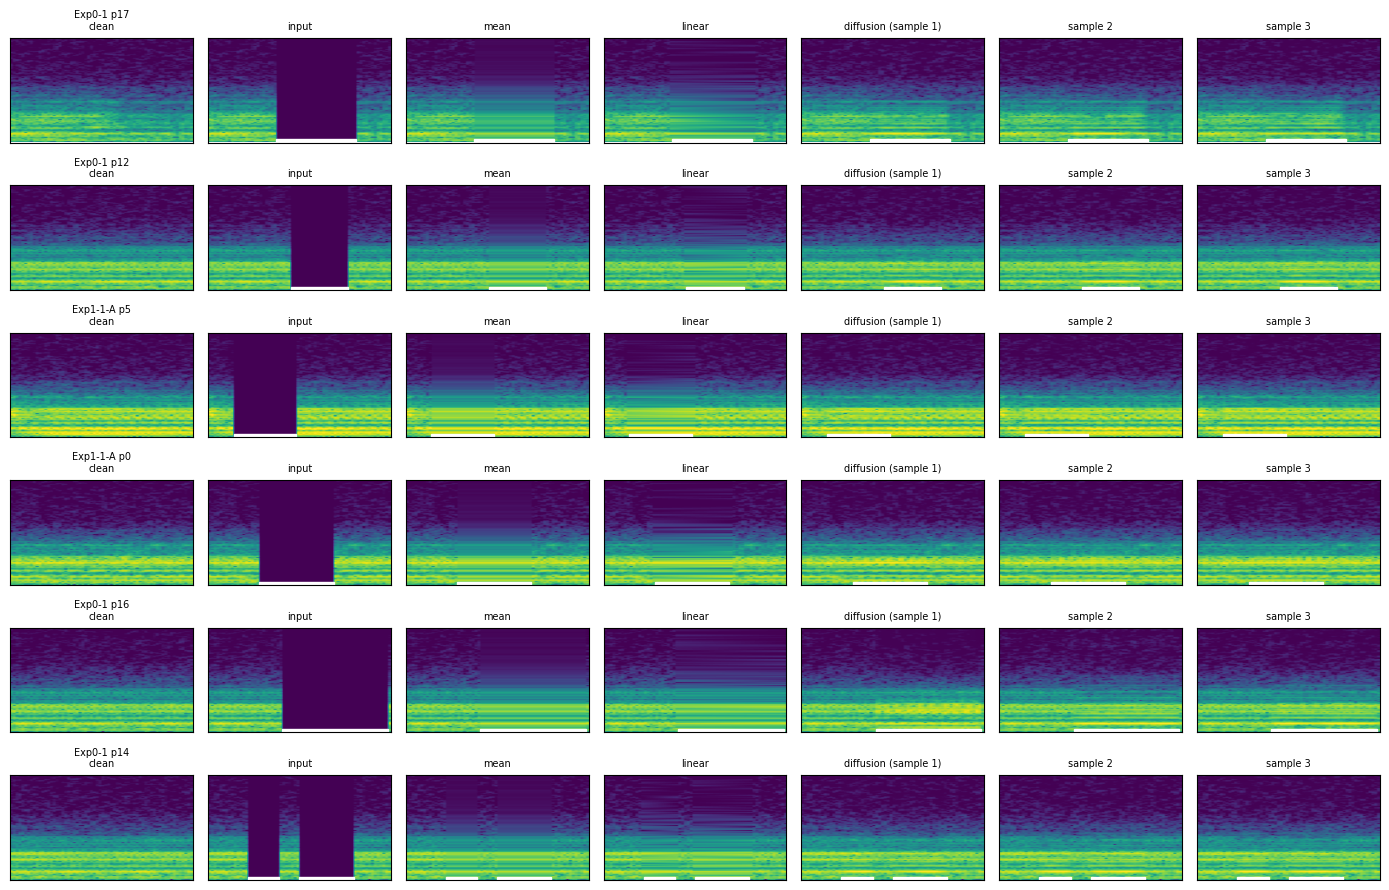

In [6]:
def show(ax, x, title, mask=None, hatch_gap=False):
    ax.imshow(x, origin="lower", aspect="auto", vmin=-100, vmax=-20, extent=[0, N_FRAMES * FRAME_S * 1000, 0, N_BINS * BIN_HZ / 1000])
    ax.set_title(title, fontsize=7); ax.set_xticks([]); ax.set_yticks([])
    if mask is not None:
        edges = np.flatnonzero(np.diff(np.concatenate([[0], mask.astype(int), [0]])))
        for a, b in zip(edges[::2], edges[1::2]):
            ax.axvspan(a * FRAME_S * 1000, b * FRAME_S * 1000, ymin=0, ymax=0.03, color="w")


def example_rows(split, n, rng_seed=0):
    clean, mask, meta = data[split]
    order = np.argsort(-metrics[(metrics.split == split) & (metrics.method == "mean")].longest_span_ms.values)
    rng = np.random.default_rng(rng_seed)
    return rng.choice(order[: max(n * 4, 8)], n, replace=False)


cols_ = ["clean", "input", "mean", "linear", "diffusion (sample 1)", "sample 2", "sample 3"]
rows = [("test", i) for i in example_rows("test", 6)]
fig, ax = plt.subplots(len(rows), len(cols_), figsize=(2.0 * len(cols_), 1.5 * len(rows)))
for r, (split, i) in enumerate(rows):
    clean, mask, meta = data[split]
    samples = preds[f"{split}_diffusion_samples"].astype(np.float32)
    imgs = [clean[i], apply_mask(clean[i], mask[i], fill=-100), preds[f"{split}_mean"][i], preds[f"{split}_linear"][i],
            samples[0, i], samples[1 % len(samples), i], samples[2 % len(samples), i]]
    for c, (img, name) in enumerate(zip(imgs, cols_)):
        show(ax[r, c], np.asarray(img, dtype=np.float32), (f"{meta.session.iloc[i]} p{meta.path_idx.iloc[i]}\n" if c == 0 else "") + name if r == 0 or c == 0 else name, mask[i] if c else None)
plt.tight_layout(); plt.show()

## 6. What the gap spectrum looks like

Gap-averaged spectrum (0-3 kHz) of one test patch with a long gap: the true spectrum has harmonic peaks. A good fill reproduces them.

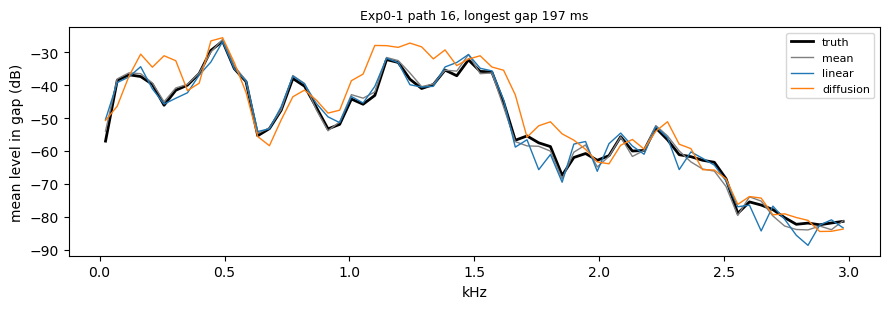

In [7]:
split = "test"; clean, mask, meta = data[split]
mm = metrics[(metrics.split == split) & (metrics.method == "mean")].reset_index(drop=True)
i = int(mm.longest_span_ms.idxmax())
f = (np.arange(LOW_BAND_BINS) + 0.5) * BIN_HZ / 1000
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(f, clean[i][:LOW_BAND_BINS][:, mask[i]].mean(axis=1), "k", lw=2, label="truth")
for name in ["mean", "linear", "diffusion"]:
    ax.plot(f, preds[f"{split}_{name}"][i].astype(np.float32)[:LOW_BAND_BINS][:, mask[i]].mean(axis=1), color=COLORS[name], label=name, lw=1)
ax.set_xlabel("kHz"); ax.set_ylabel("mean level in gap (dB)"); ax.legend(fontsize=8); ax.set_title(f"{meta.session.iloc[i]} path {meta.path_idx.iloc[i]}, longest gap {mm.longest_span_ms[i]:.0f} ms", fontsize=9)
plt.tight_layout(); plt.show()

## 7. Can you tell the gap was filled?

MAE says how far a fill is from the truth, not whether it *looks* real: in the examples above the mean-fill and linear gaps are easy to spot as smooth blocks, while the diffusion gaps blend in. This section measures that with a **detector**: for every missing frame there is the real version and the filled version, and a logistic regression is trained to separate them. The score is ROC AUC: **0.5 = it cannot tell, 1.0 = every filled frame is spotted**.

* The detector is told where the gap is, and is always tested on a session it was not trained on (leave-one-session-out over the 3 test sessions).
* Each frame is described by 68 numbers from the 0-3 kHz band: roughness across frequency, level offset, spread, change from the previous frame, and the spectrum minus the patch's observed mean.
* A stronger detector would find more, so read the AUC as a lower bound on detectability.

Code: `src/mtcut/detect.py`, `scripts/eval_detectability.py`.

detector AUC; per-session columns = held-out session,AUC (all sessions),Exp0-1,Exp1-1-A,Exp1-8
method,,,,
mean,0.981,0.997,0.997,0.818
linear,0.998,0.999,0.997,0.999
diffusion,0.763,0.869,0.670,0.793


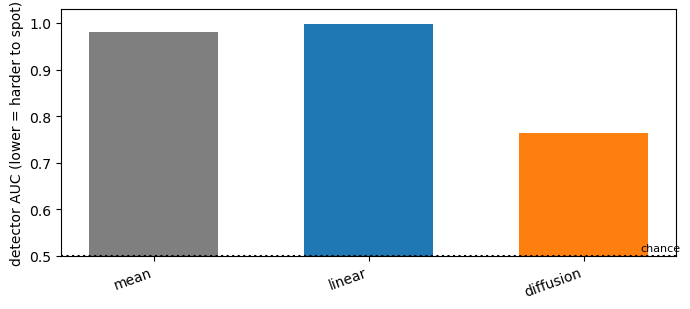

In [8]:
det = pd.read_csv(MASKED_DIR / "detectability.csv").set_index("method").reindex(METHODS)
display(det.round(3).rename(columns={"auc": "AUC (all sessions)"}).rename_axis(columns="detector AUC; per-session columns = held-out session"))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(METHODS)), det.auc, 0.6, color=[COLORS[m] for m in METHODS])
ax.axhline(0.5, color="k", ls=":"); ax.text(len(METHODS) - 0.55, 0.51, "chance", ha="right", fontsize=8)
ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS, rotation=20, ha="right"); ax.set_ylim(0.5, 1.03)
ax.set_ylabel("detector AUC (lower = harder to spot)")
plt.tight_layout(); plt.show()

## 8. Slide figures

Two simplified figures for presentation, using diffusion (a single sample per patch).

* **Table:** the three metrics, best value per column in bold. *MAE* is over the missing frames, all 128 bins (0-6 kHz). *Profile correlation* (`profile_corr`) and *std ratio* (`std_ratio`) are computed over the missing frames in the 0-3 kHz band, where the energy is.
* **Examples:** one test patch per held-out session, with a gap of about 80 ms (not the best or worst cases). The number in each corner is that patch's MAE (0-6 kHz); the images show only 0-3 kHz.

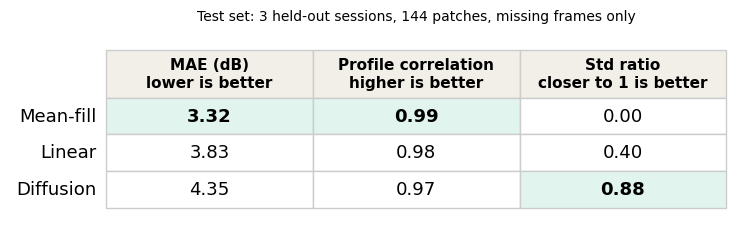

In [9]:
SLIDE = {"mean": "Mean-fill", "linear": "Linear", "diffusion": "Diffusion"}

t = metrics[metrics.method.isin(SLIDE)].groupby("method")[["mae_db", "profile_corr", "std_ratio"]].mean().loc[list(SLIDE)]
heads = ["MAE (dB)\nlower is better", "Profile correlation\nhigher is better", "Std ratio\ncloser to 1 is better"]
best = [t.mae_db.idxmin(), t.profile_corr.idxmax(), (t.std_ratio - 1).abs().idxmin()]
cells = [[f"{r.mae_db:.2f}", f"{r.profile_corr:.2f}", f"{r.std_ratio:.2f}"] for r in t.itertuples()]
fig, ax = plt.subplots(figsize=(8, 2.6)); ax.axis("off")
tb = ax.table(cellText=cells, rowLabels=[SLIDE[i] for i in t.index], colLabels=heads, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(13); tb.scale(1, 2.2)
for (r, c), cl in tb.get_celld().items():
    cl.set_edgecolor("#cccccc")
    if r == 0:
        cl.set_facecolor("#f1efe8"); cl.set_text_props(fontsize=11, weight="bold"); cl.set_height(cl.get_height() * 1.3)
    if r > 0 and c >= 0 and t.index[r - 1] == best[c]:
        cl.set_text_props(weight="bold"); cl.set_facecolor("#e1f5ee")
    if c == -1:
        cl.set_text_props(ha="right"); cl.set_edgecolor("white")
n_test = metrics[metrics.method == "mean"].shape[0]
ax.set_title(f"Test set: 3 held-out sessions, {n_test} patches, missing frames only", fontsize=10, pad=6)
plt.show()

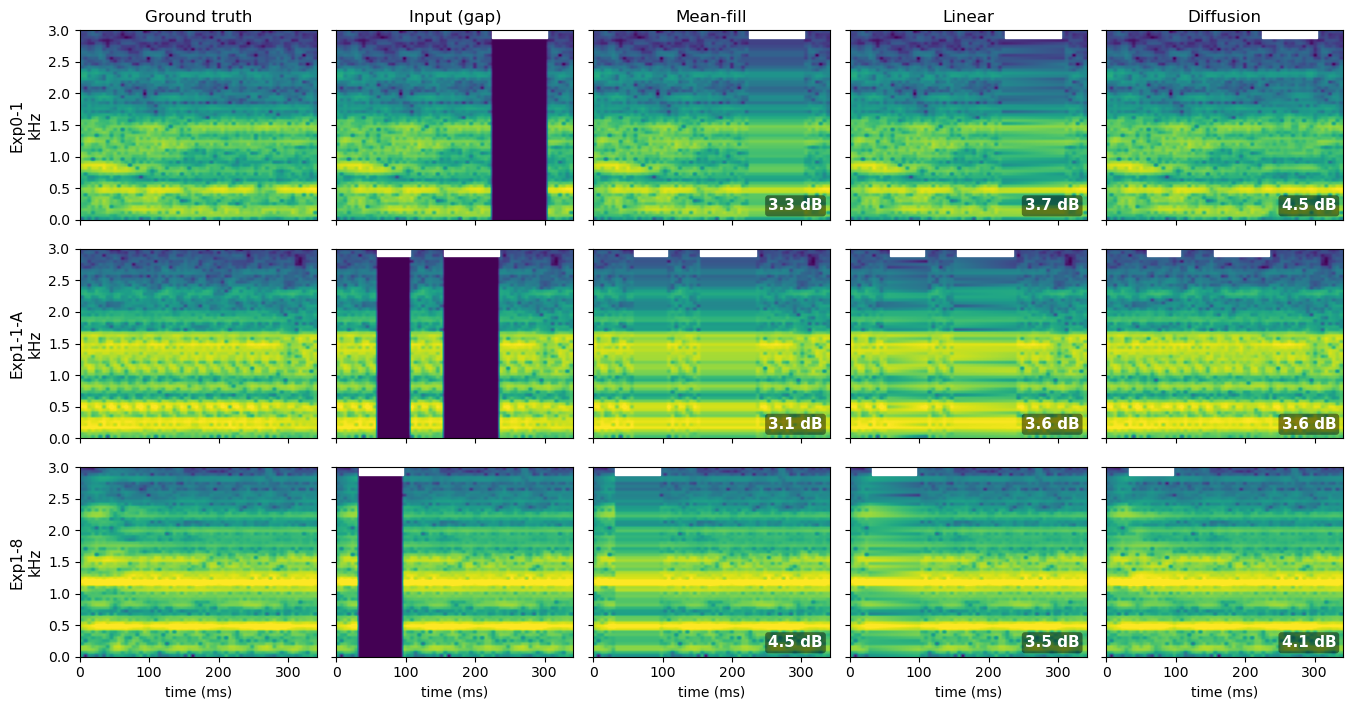

In [10]:
clean, mask, meta = data["test"]
span = metrics[metrics.method == "mean"].set_index("patch_idx").longest_span_ms
picks = []
for sess in sorted(meta.session.unique()):
    s_ = span[meta.index[meta.session == sess]]
    s_ = s_[(s_ >= 55) & (s_ <= 110)]
    if len(s_):
        picks.append((sess, (s_ - 80).abs().idxmin()))
pos = {i: k for k, i in enumerate(meta.index)}
cols_ = [("clean", "Ground truth"), ("input", "Input (gap)"), ("mean", "Mean-fill"), ("linear", "Linear"), ("diffusion", "Diffusion")]
fig, ax = plt.subplots(len(picks), len(cols_), figsize=(13.5, 2.4 * len(picks)), sharex=True, sharey=True, squeeze=False)
for r, (sess, pid) in enumerate(picks):
    k = pos[pid]
    for c, (key, name) in enumerate(cols_):
        img = clean[k] if key == "clean" else apply_mask(clean[k], mask[k], fill=-100) if key == "input" else preds[f"test_{key}"][k].astype(np.float32)
        a = ax[r, c]
        a.imshow(img[:LOW_BAND_BINS], origin="lower", aspect="auto", vmin=-100, vmax=-20, extent=[0, N_FRAMES * FRAME_S * 1000, 0, LOW_BAND_BINS * BIN_HZ / 1000])
        if key != "clean":
            e = np.flatnonzero(np.diff(np.concatenate([[0], mask[k].astype(int), [0]])))
            for s0, s1 in zip(e[::2], e[1::2]):
                a.axvspan(s0 * FRAME_S * 1000, s1 * FRAME_S * 1000, ymin=0.96, ymax=1, color="white")
        if r == 0: a.set_title(name, fontsize=12)
        if key in SLIDE:
            mae = metrics[(metrics.method == key) & (metrics.patch_idx == pid) & (metrics.split == "test")].mae_db.iloc[0]
            a.text(0.97, 0.05, f"{mae:.1f} dB", transform=a.transAxes, ha="right", color="white", fontsize=11, weight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.45, lw=0))
        if c == 0: a.set_ylabel(f"{sess}\nkHz", fontsize=11)
        if r == len(picks) - 1: a.set_xlabel("time (ms)")
plt.tight_layout(); plt.show()

## 9. Takeaways

**Result: on this task the diffusion model does not beat the simplest baseline on accuracy, but it is much harder to spot.**

| test (3 held-out IMI sessions, 144 patches) | mean | linear | diffusion |
|---|---|---|---|
| MAE 0-3 kHz (dB), lower is better | **3.75** | 4.34 | 5.30 |
| MAE all bins (dB) | **3.32** | 3.83 | 4.35 |
| Detector AUC (0.5 = cannot tell), lower is harder to spot | 0.98 | 1.00 | **0.76** |

* **Mean-fill wins every error metric**, in each of the 3 test sessions and in every gap-length bucket, including gaps over 100 ms (up to ~200 ms). Linear is close for gaps under 30 ms (3.82 against 3.75) and falls behind as gaps grow.
* **Why:** within a 0.36 s window the cutting sound is close to stationary: harmonic stripes plus noise. The mean of the observed frames already predicts the gap well. What it cannot predict is the random fine texture, which is noise-like, so no method can match it frame by frame. Error metrics punish a realistic-but-different texture, so a diffusion sample pays roughly the noise twice.
* **What diffusion does give:** a realistic texture. Its `std_ratio` is 0.88 against 0 for mean-fill and 0.40 for linear, with the harmonic stripes still recovered (`profile_corr` 0.97 versus 0.99). If downstream use needs fills that look like real signal, that is a real advantage. Accuracy is not.
* **Detectability confirms the visual impression (section 7).** A logistic-regression detector that is told where the gap is finds the mean-fill and linear gaps almost every time (AUC 0.98 and 1.00). A single diffusion sample is the hardest to spot (AUC 0.76), but it is not undetectable, and a stronger detector would find more, so read these as lower bounds.
* **Removing the loudness gate changed nothing material.** The first version of the dataset dropped windows less than 3 dB above the session idle level. With those windows back in (and the model retrained), the numbers moved by less than 0.1 dB and the ranking is identical.

**Caveats**
* Three test sessions, all scored normal (no chatter), and `Exp0-1` alone supplies 103 of the 144 patches, so the pooled averages lean on one session. The ranking holds in each session, but the sizes of the differences are not precise. The model is small (3.6M parameters) and was trained for 35 minutes (8.6k steps); validation loss had flattened, but a longer or larger run was not tried.
* The loudest chatter cuts are not in the data, because they clip on sensor 2.
* Mask type is easy (stationary signal, short gaps). Higher error for diffusion here does not mean it would lose on harder cases.

**Where a generative model could earn its cost (not tested)**
* Longer gaps (200 ms and more) or longer context windows, where the signal changes within the gap.
* Non-stationary events, such as tool entry and exit or chatter onset, where an average is wrong.
* Real clipped samples (declipping) rather than artificial dropouts, which was the original motivation.
* A downstream check was run in notebook 04: filling gaps with diffusion does not improve a chatter classifier compared with mean-fill.